# Import Libraries

In [9]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests

# **1. Download Financial Data**

Download **10** years of USD Index. Columns Volume, Dividends and Stock Splits are not required, since they are constant and equal to 0.0

In [10]:
ticker_symbol = 'DX-Y.NYB'

ticker = yf.Ticker(ticker_symbol)
df = ticker.history(period='10y').drop(columns=['Volume', 'Dividends', 'Stock Splits']).reset_index(drop=False)
df

,Date,Open,High,Low,Close
0,2016-10-27 00:00:00-04:00,98.620003,99.029999,98.500000,98.889999
1,2016-10-28 00:00:00-04:00,98.919998,98.940002,98.239998,98.349998
2,2016-10-31 00:00:00-04:00,98.320000,98.699997,98.290001,98.449997
3,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997
4,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002
...,...,...,...,...,...
2509,2026-10-21 00:00:00-04:00,101.779999,101.839996,101.639999,101.779999
2510,2026-10-22 00:00:00-04:00,101.709999,101.879997,101.449997,101.610001
2511,2026-10-23 00:00:00-04:00,101.570000,101.849998,101.489998,101.809998
2512,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999


## Περιγραφή Μεταβλητών

*   Open : Τιμή στο άνοιγμα της ημέρας.
*   High : Υψηλότερη τιμή μέσα στην ημέρα.
*   Low : Χαμηλότερη τιμή μέσα στην ημέρα.
*   Close : Τιμή στο κλείσιμο της ημέρας.

## Μέση Τιμή, Τυπική Απόκλιση, Ελάχιστη και Μέγιστη τιμή μεταβλητών

In [11]:
df.describe().loc[['mean', 'std', 'min', 'max']].round(2)

,Open,High,Low,Close
mean,98.80,99.10,98.51,98.81
std,4.97,5.02,4.91,4.97
min,88.57,89.00,88.25,88.59
max,114.19,114.78,113.33,114.11


Οι τέσσερις μεταβλητές έχουν σχεδόν ίδια μέση τιμή και τυπική απόκλιση, γιατί μέσα σε μία ημέρα το δολάριο κινείται πολύ λίγο σε σχέση με τις αλλαγές που κάνει μέσα σε 10 χρόνια.

## Construct Line Plot of HLC Data

In [12]:
fig = px.line(df, x='Date', y=['High', 'Close', 'Low'], title='USD Price Index - High, Low, Close (10 years)')
fig.update_layout(width=1300, height=650)
fig.show()

# **2. Ανάλυση Χρονοσειρών**


Από το γράφημα οι χρονοσειρές High, Low και Close είναι μη στάσιμες.

Συγκεκριμένα:

- Έχουν τάση: η τιμή ανεβαίνει ή κατεβαίνει για μεγάλα διαστήματα (μήνες ή χρόνια) και δεν κινείται γύρω από ένα σταθερό επίπεδο.
- Η μέση τιμή αλλάζει στον χρόνο: π.χ. η μέση τιμή ενός έτους διαφέρει πολύ από αυτήν ενός άλλου.
- Η διακύμανση δεν είναι σταθερή: υπάρχουν περίοδοι με μεγάλες αυξομειώσεις και περίοδοι σχετικής στασιμότητας.

# **3. Στατιστικά Test ADF & KPSS**

In [13]:
for col in ['Open', 'High', 'Low', 'Close']:
    adf_p_value = adfuller(df[col], autolag='AIC')[1]
    kpss_p_value = kpss(df[col], regression='c', nlags='auto')[1]
    print(f'{col}: ADF p-value = {adf_p_value:.4f}, KPSS p-value = {kpss_p_value:.4f}')

/tmp/ipykernel_1000/2290364826.py:2: FutureWarning:

adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.

/tmp/ipykernel_1000/2290364826.py:3: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.

/tmp/ipykernel_1000/2290364826.py:3: FutureWarning:

kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current 

Open: ADF p-value = 0.3402, KPSS p-value = 0.0100
High: ADF p-value = 0.3394, KPSS p-value = 0.0100
Low: ADF p-value = 0.2975, KPSS p-value = 0.0100
Close: ADF p-value = 0.3375, KPSS p-value = 0.0100


/tmp/ipykernel_1000/2290364826.py:2: FutureWarning:

adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.

/tmp/ipykernel_1000/2290364826.py:3: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.

/tmp/ipykernel_1000/2290364826.py:3: FutureWarning:

kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current 

Σε όλες τις μεταβλητές το ADF έχει p-value ≥ 0.05 και το KPSS p-value < 0.05, άρα έχουμε ένδειξη **μη στασιμότητας**.

# **4. Train-Test Split**

Test set should start 1 time step after the end of train set.

In [35]:
train_size = 0.7
history_size = 30

num_train_samples = int(df.shape[0]*train_size)
train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples - history_size:]

train_df.shape, test_df.shape

((1759, 5), (785, 5))

# **5. Linear Regression**


## Construct Timeframes

*   x = <x[0], x[1], x[2], ... x[H-1]>
*   y = x[H]

where x is (Open(t), High(t), Low(t), Close(t))

**Important: Past target must be included in x to achieve good accuracy**

In [37]:
ef construct_timeframes(df, H):
    inputs = df.drop(columns=['Date']).to_numpy(dtype=np.float64)
    x = np.array([inputs[i-H: i].flatten() for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

# Verify Timeframes

In [38]:
x_train, y_train = construct_timeframes(train_df, H=2)
print('x:', x_train[0],'\ny:', y_train[0])

x: [98.62000275 99.02999878 98.5        98.88999939 98.91999817 98.94000244
 98.23999786 98.34999847] 
y: 98.44999694824219


In [22]:
train_df.head(3)

,Date,Open,High,Low,Close
0,2016-10-27 00:00:00-04:00,98.620003,99.029999,98.500000,98.889999
1,2016-10-28 00:00:00-04:00,98.919998,98.940002,98.239998,98.349998
2,2016-10-31 00:00:00-04:00,98.320000,98.699997,98.290001,98.449997


## Train - Test MAE για H = 1, 5, 15, 30

Μετρική: MAE (Mean Absolute Error)

In [39]:
H_values = [1, 5, 15, 30]

metrics = []
for H in H_values:
    train_df = df.iloc[:num_train_samples]
    test_df = df.iloc[num_train_samples - H:]

    x_train, y_train = construct_timeframes(train_df, H)
    x_test, y_test = construct_timeframes(test_df, H)

    model = LinearRegression()
    model.fit(x_train, y_train)

    train_mae = mean_absolute_error(y_true=y_train, y_pred=model.predict(x_train))
    test_mae = mean_absolute_error(y_true=y_test, y_pred=model.predict(x_test))
    metrics.append({'H': H, 'Dataset': 'Train', 'MAE': train_mae})
    metrics.append({'H': H, 'Dataset': 'Test', 'MAE': test_mae})

metrics_df = pd.DataFrame(metrics)
metrics_df.pivot(index='H', columns='Dataset', values='MAE').round(4)

Dataset,Test,Train
H,,
1,0.3094,0.3107
5,0.3084,0.3100
15,0.3158,0.3044
30,0.3239,0.3002


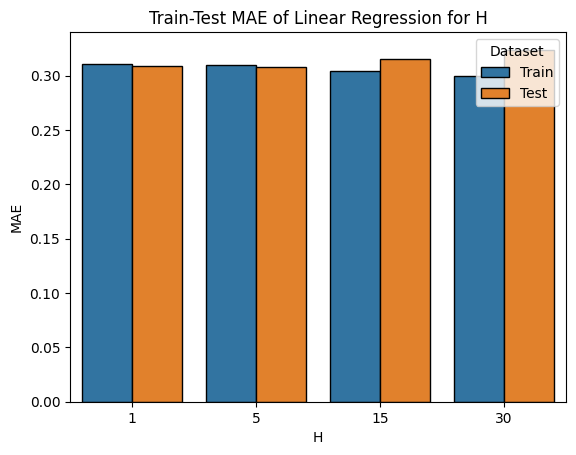

In [40]:
= sns.barplot(metrics_df, x='H', y='MAE', hue='Dataset', edgecolor='black')
ax.set_title('Train-Test MAE of Linear Regression for H')
plt.show()

Για σύγκριση, υπολογίζουμε το MAE της πιο απλής πρόβλεψης: η αυριανή τιμή είναι ίδια με τη σημερινή, δηλαδή Close(t+1) = Close(t).

In [41]:
close = df['Close'].to_numpy()
simple_test_mae = mean_absolute_error(y_true=close[num_train_samples:], y_pred=close[num_train_samples - 1:-1])
print(f'Test MAE αν προβλέπουμε Close(t+1) = Close(t): {simple_test_mae:.4f}')

Test MAE αν προβλέπουμε Close(t+1) = Close(t): 0.3078


- Το MAE είναι μικρό σε σχέση με την τιμή του δείκτη (~100), αλλά είναι σχεδόν ίδιο με το MAE της απλής πρόβλεψης Close(t+1) = Close(t).
- Μεγαλύτερο H δε βελτιώνει την πρόβλεψη στο test. Το train MAE μειώνεται λίγο, αλλά το test MAE μένει ίδιο ή αυξάνεται, γιατί τα παλιά δεδομένα προσθέτουν περισσότερο θόρυβο παρά πληροφορία (μικρό overfitting).

# **6. Visualize Predictions (H = 30)**

In [43]:
train_dates = train_df['Date'].iloc[history_size:]
test_dates = test_df['Date'].iloc[history_size:]

# Create figure
fig = go.Figure()

# Training data (last history_size samples only)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_train)[-history_size:],
    mode='lines',
    name='Train (Actual)',
    line=dict(color='royalblue', width=2)
))

# Training predictions (last history_size samples only)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_pred_train)[-history_size:],
    mode='lines',
    name='Train (Predicted)',
    line=dict(color='orange', width=2)
))

# Test actual values
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_test),
    mode='lines',
    name='Test (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))

# Vertical dashed line separating train/test
fig.add_shape(
    type='line',
    x0=test_dates.iloc[0],
    x1=test_dates.iloc[0],
    y0=0,
    y1=1,
    xref='x',
    yref='paper',
    line=dict(color='black', width=2, dash='dash')
)

# Prediction line for test set
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_pred),
    mode='lines',
    name='Test (Predicted)',
    line=dict(color='#E63946', width=2.5)
))

# Layout
fig.update_layout(
    title='USD Price Index — Close Price Prediction (H=30)',
    xaxis_title='Date',
    yaxis_title='Price ($)',
    template='plotly_white',
    legend=dict(x=0.01, y=0.99),
    hovermode='x unified',
    width=1300,
    height=600
)

fig.show()

Οι προβλεπόμενες τιμές ακολουθούν πολύ καλά τις πραγματικές, αλλά με λίγη καθυστέρηση: η κόκκινη γραμμή είναι σχεδόν η μπλε μετατοπισμένη μία μέρα δεξιά.
Δηλαδή το μοντέλο δίνει περίπου την τιμή της προηγούμενης ημέρας.

# **7. Apply Log Returns Transformation**

In [48]:


vars = ['Open', 'High', 'Low', 'Close']
df_logr = df.copy()
df_logr[vars] = np.log(df_logr[vars]/df_logr[vars].shift(1))

# Αφαιρούμε την πρώτη γραμμή (NaN) και κρατάμε τις απόλυτες τιμές Close για τις ίδιες ημέρες
df_logr = df_logr.iloc[1:].reset_index(drop=True)
close = df['Close'].iloc[1:].reset_index(drop=True).to_numpy()
df_logr

,Date,Open,High,Low,Close
0,2016-10-28 00:00:00-04:00,0.003037,-0.000909,-0.002643,-0.005476
1,2016-10-31 00:00:00-04:00,-0.006084,-0.002429,0.000509,0.001016
2,2016-11-01 00:00:00-04:00,0.000712,-0.002231,-0.006635,-0.007647
3,2016-11-02 00:00:00-04:00,-0.006526,-0.006929,-0.004722,-0.003075
4,2016-11-03 00:00:00-04:00,-0.003792,-0.003483,-0.001442,-0.002467
...,...,...,...,...,...
2508,2026-10-21 00:00:00-04:00,-0.001963,-0.001374,0.001280,0.000491
2509,2026-10-22 00:00:00-04:00,-0.000688,0.000393,-0.001871,-0.001672
2510,2026-10-23 00:00:00-04:00,-0.001377,-0.000294,0.000394,0.001966
2511,2026-10-26 00:00:00-04:00,0.002065,0.002060,0.000886,0.001472


# Convert Log Returns to Absolute Price

$lr_{t+1} = \ln(\frac{y_{t+1}}{y_{t}})$

$y_{t+1} = y_t * e^{lr_{t+1}}$

Inevitably, the first sample will be lost, as its log-return transformation cannot be defined (x[-1] does not exist).

In [45]:
def log_returns_to_absolute_prices(prices, log_returns):
    return prices * np.exp(log_returns)

## Train - Test MAE με Log Returns για H = 1, 5, 15, 30

In [33]:
num_train_samples_logr = int(df_logr.shape[0]*train_size)

metrics_logr = []
for H in H_values:
    train_logr = df_logr.iloc[:num_train_samples_logr]
    test_logr = df_logr.iloc[num_train_samples_logr - H:]

    x_train, y_train = construct_timeframes(train_logr, H)
    x_test, y_test = construct_timeframes(test_logr, H)

    model = LinearRegression()
    model.fit(x_train, y_train)

    # Απόλυτες τιμές: πρόβλεψη = Close(t-1) * e^(προβλεπόμενο log return)
    close_train = close[:num_train_samples_logr]
    close_test = close[num_train_samples_logr - H:]
    y_pred_train = log_returns_to_absolute_prices(close_train[H-1:-1], model.predict(x_train))
    y_pred_test = log_returns_to_absolute_prices(close_test[H-1:-1], model.predict(x_test))

    train_mae = mean_absolute_error(y_true=close_train[H:], y_pred=y_pred_train)
    test_mae = mean_absolute_error(y_true=close_test[H:], y_pred=y_pred_test)
    metrics_logr.append({'H': H, 'Dataset': 'Train', 'MAE': train_mae})
    metrics_logr.append({'H': H, 'Dataset': 'Test', 'MAE': test_mae})

metrics_logr_df = pd.DataFrame(metrics_logr)
metrics_logr_df.pivot(index='H', columns='Dataset', values='MAE').round(4)

Dataset,Test,Train
H,,
1,0.3086,0.3097
5,0.3076,0.3089
15,0.3148,0.3040
30,0.3229,0.2991


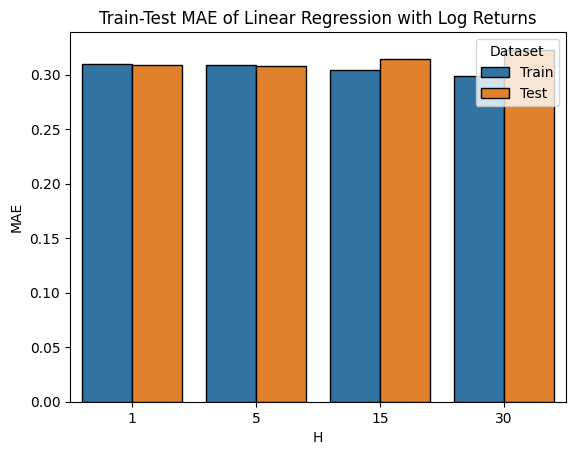

In [34]:
ax = sns.barplot(metrics_logr_df, x='H', y='MAE', hue='Dataset', edgecolor='black')
ax.set_title('Train-Test MAE of Linear Regression with Log Returns')
plt.show()

## Σύγκριση με το Ερώτημα 5

In [49]:
comparison_df = pd.DataFrame({
    'H': H_values,
    'Test MAE (Absolute Prices)': metrics_df[metrics_df['Dataset'] == 'Test']['MAE'].to_numpy(),
    'Test MAE (Log Returns)': metrics_logr_df[metrics_logr_df['Dataset'] == 'Test']['MAE'].to_numpy(),
})
comparison_df.round(4)

,H,Test MAE (Absolute Prices),Test MAE (Log Returns)
0,1,0.3094,0.3086
1,5,0.3084,0.3076
2,15,0.3158,0.3148
3,30,0.3239,0.3229


Παρατηρήσεις

- Σε απόλυτες τιμές τα δύο μοντέλα έχουν πολύ κοντινό MAE. Οι προβλεπόμενες log returns είναι πολύ κοντά στο 0, άρα η πρόβλεψη είναι πάλι περίπου η τιμή της προηγούμενης ημέρας.


In [ ]:
log_returns_to_absolute_prices(
    prices=valid_df['Close'].iloc[: -1].to_numpy(),
    log_returns=valid_df['CLose-Log-Returns'].iloc[1:].to_numpy()
)

array([93.94999695, 93.86000061, 93.34999847, 94.12000275, 93.87999725])

# **8. Granger Causality Test**

Variables that can estimate the target variable are considered beneficial.

Το test χρειάζεται στάσιμες χρονοσειρές, οπότε το εφαρμόζουμε στα log returns. Χρησιμοποιούμε μόνο το train set.

In [50]:
data = df.iloc[:num_train_samples][['Close', 'Open']]

# Computing log-returns (converting to stationary series).
data = np.log(data/data.shift(1)).dropna()

# Test up to history_size lags
results = grangercausalitytests(data[['Close', 'Open']], maxlag=history_size)

# Extract p-values
p_values = {
    lag: results[lag][0]['ssr_ftest'][1]
    for lag in range(1, history_size + 1)
}
results_df = pd.DataFrame({'Lag (H)': list(p_values.keys()), 'P-value': list(p_values.values())})
results_df['Significant'] = results_df['P-value'] < 0.05
results_df

,Lag (H),P-value,Significant
0,1,0.217111,False
1,2,0.803355,False
2,3,0.525259,False
3,4,0.782539,False
4,5,0.021278,True
5,6,0.629851,False
6,7,0.753180,False
7,8,0.404007,False
8,9,0.285537,False
9,10,0.532537,False


In [51]:
results_df[results_df['Significant']]

,Lag (H),P-value,Significant
4,5,0.021278,True


Τα lags με P-value < 0.05 (Significant = True) είναι τα χρονικά βήματα στα οποία το Open δίνει χρήσιμη πληροφορία για την πρόβλεψη του Close, πέρα από αυτήν που ήδη δίνουν οι προηγούμενες τιμές του Close. Το πιο σημαντικό είναι συνήθως αμέσως προηγούμενη ημέρα.

# **9. Extracting Temporal Features**

In [52]:
sp500 = yf.Ticker('^GSPC').history(period='10y').reset_index(drop=False)[['Date', 'Close']]
sp500 = sp500.rename(columns={'Close': 'SP500'})

df_features = df.merge(sp500, on='Date', how='left')
df_features['SP500'] = df_features['SP500'].ffill()   # ημέρες χωρίς συναλλαγές στο S&P500 παίρνουν την προηγούμενη τιμή
df_features = df_features.dropna().reset_index(drop=True)

# Calendar features
df_features['Month'] = df_features['Date'].dt.month
df_features['DayOfWeek'] = df_features['Date'].dt.dayofweek  # Monday=0, Sunday=6

# US & NYSE holidays
us_holidays = holidays.country_holidays('US')
nyse_holidays = holidays.financial_holidays('NYSE')
df_features['Holiday'] = df_features['Date'].dt.date.map(lambda d: int(d in us_holidays or d in nyse_holidays))

df_features

,Date,Open,High,Low,Close,SP500,Month,DayOfWeek,Holiday
0,2016-10-27 00:00:00-04:00,98.620003,99.029999,98.500000,98.889999,2133.040039,10,3,0
1,2016-10-28 00:00:00-04:00,98.919998,98.940002,98.239998,98.349998,2126.409912,10,4,0
2,2016-10-31 00:00:00-04:00,98.320000,98.699997,98.290001,98.449997,2126.149902,10,0,0
3,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997,2111.719971,11,1,0
4,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002,2097.939941,11,2,0
...,...,...,...,...,...,...,...,...,...
2509,2026-10-21 00:00:00-04:00,101.779999,101.839996,101.639999,101.779999,7757.169922,10,2,0
2510,2026-10-22 00:00:00-04:00,101.709999,101.879997,101.449997,101.610001,7663.430176,10,3,0
2511,2026-10-23 00:00:00-04:00,101.570000,101.849998,101.489998,101.809998,7623.680176,10,4,0
2512,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999,7676.770020,10,0,0


In [53]:
df_features['Holiday'].value_counts()

,count
Holiday,
0,2491
1,23


## Construct Timeframes με μελλοντικά χαρακτηριστικά


*   x = <x[0], x[1], ... x[H-1]> + (Month, DayOfWeek, Holiday) της ημέρας H
*   y = Close[H]

όπου x[i] = (Open(i), High(i), Low(i), Close(i), SP500(i))

In [54]:
past_features = ['Open', 'High', 'Low', 'Close', 'SP500']
future_features = ['Month', 'DayOfWeek', 'Holiday']

def construct_timeframes_with_future(df, H):
    inputs = df[past_features].to_numpy(dtype=np.float64)
    future = df[future_features].to_numpy(dtype=np.float64)
    x = np.array([np.concatenate([inputs[i-H: i].flatten(), future[i]]) for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

## Visualize Predictions (H = 30)

In [55]:
num_train_samples_f = int(df_features.shape[0]*train_size)
train_df = df_features.iloc[:num_train_samples_f]
test_df = df_features.iloc[num_train_samples_f - history_size:]

x_train, y_train = construct_timeframes_with_future(train_df, history_size)
x_test, y_test = construct_timeframes_with_future(test_df, history_size)

model = LinearRegression()
model.fit(x_train, y_train)
y_pred_train = model.predict(x_train)
y_pred = model.predict(x_test)

train_mae = mean_absolute_error(y_true=y_train, y_pred=y_pred_train)
test_mae = mean_absolute_error(y_true=y_test, y_pred=y_pred)
print(f'Train MAE: {train_mae:.4f}')
print(f'Test MAE: {test_mae:.4f}')

Train MAE: 0.2923
Test MAE: 0.3368


In [56]:
train_dates = train_df['Date'].iloc[history_size:]
test_dates = test_df['Date'].iloc[history_size:]

fig = go.Figure()

fig.add_trace(go.Scatter(x=train_dates.iloc[-history_size:], y=np.ravel(y_train)[-history_size:],
                         mode='lines', name='Train (Actual)', line=dict(color='royalblue', width=2)))
fig.add_trace(go.Scatter(x=train_dates.iloc[-history_size:], y=np.ravel(y_pred_train)[-history_size:],
                         mode='lines', name='Train (Predicted)', line=dict(color='orange', width=2)))
fig.add_trace(go.Scatter(x=test_dates, y=np.ravel(y_test),
                         mode='lines', name='Test (Actual)', line=dict(color='royalblue', width=2, dash='dash')))
fig.add_shape(type='line', x0=test_dates.iloc[0], x1=test_dates.iloc[0], y0=0, y1=1,
              xref='x', yref='paper', line=dict(color='black', width=2, dash='dash'))
fig.add_trace(go.Scatter(x=test_dates, y=np.ravel(y_pred),
                         mode='lines', name='Test (Predicted)', line=dict(color='#E63946', width=2.5)))

fig.update_layout(title='USD Price Index — Close Price Prediction with S&P500 and Calendar Features (H=30)',
                  xaxis_title='Date', yaxis_title='Price ($)', template='plotly_white',
                  legend=dict(x=0.01, y=0.99), hovermode='x unified', width=1300, height=600)
fig.show()

## Σύγκριση με το Ερώτημα 6

In [57]:
test_mae_q6 = metrics_df[(metrics_df['H'] == 30) & (metrics_df['Dataset'] == 'Test')]['MAE'].iloc[0]
print(f'Test MAE χωρίς επιπλέον χαρακτηριστικά (ερώτημα 6): {test_mae_q6:.4f}')
print(f'Test MAE με επιπλέον χαρακτηριστικά (ερώτημα 9):    {test_mae:.4f}')

Test MAE χωρίς επιπλέον χαρακτηριστικά (ερώτημα 6): 0.3239
Test MAE με επιπλέον χαρακτηριστικά (ερώτημα 9):    0.3368


## Παρατηρήσεις

- Με τα επιπλέον χαρακτηριστικά οι προβλέψεις συνεχίζουν να ακολουθούν την πραγματική τιμή με **καθυστέρηση μίας ημέρας**, όπως στο ερώτημα 6.
- Το S&P500 είναι κι αυτό μη στάσιμο, και στο test έχει τιμές πολύ μεγαλύτερες από αυτές που είδε το μοντέλο στο train. Γι' αυτό μπορεί να μη βοηθά ή και να χειροτερεύει λίγο το test MAE.
- Η ημέρα της εβδομάδας, ο μήνας και οι αργίες δεν επηρεάζουν ουσιαστικά την ημερήσια τιμή του δολαρίου.
- **Συμπέρασμα:** ένα γραμμικό μοντέλο πάνω σε προηγούμενες τιμές δεν καταφέρνει να προβλέψει αξιόπιστα την κίνηση του δολαρίου. Δίνει περίπου τη χθεσινή τιμή. Για καλύτερη πρόβλεψη θα χρειάζονταν άλλα χαρακτηριστικά (π.χ. επιτόκια) ή πιο σύνθετα μοντέλα.